<a href="https://colab.research.google.com/github/collinsombati/Machine-Learning/blob/main/Exploring%20mathematics%20of%20the%20data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Selecting Variables and Calculating
 Descriptive Statistics
We will select 4 key numerical variables from our rock fragmentation dataset:

Burden_m (Distance to the free face)

Powder_Factor_kg_m3 (Explosive consumption per unit volume)

UCS_MPa (Uniaxial Compressive Strength of the rock)

Mean_Fragment_Size_cm (Target output fragment size)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df' from your previous notebook is already loaded,
# or we recreate/load it here for independence:
np.random.seed(42)
n_samples = 500
burden = np.random.uniform(2.0, 5.0, n_samples)
powder_factor = np.random.uniform(0.3, 0.9, n_samples)
ucs = np.random.uniform(60, 180, n_samples)
rqd = np.random.uniform(40, 95, n_samples)
mean_fragment_size = (15.0 * burden + 0.15 * ucs + 0.25 * rqd - 45.0 * powder_factor + np.random.normal(0, 3.0, n_samples))

df = pd.DataFrame({
    'Burden_m': burden,
    'Powder_Factor_kg_m3': powder_factor,
    'UCS_MPa': ucs,
    'Mean_Fragment_Size_cm': mean_fragment_size
})

# Selected variables for analysis
selected_vars = ['Burden_m', 'Powder_Factor_kg_m3', 'UCS_MPa', 'Mean_Fragment_Size_cm']

# Calculating statistics
stats_summary = pd.DataFrame(index=['Mean', 'Median', 'Range', 'Variance', 'Standard Deviation'])

for var in selected_vars:
    col = df[var]
    mean_val = col.mean()
    median_val = col.median()
    range_val = col.max() - col.min()
    var_val = col.var()
    std_val = col.std()

    stats_summary[var] = [mean_val, median_val, range_val, var_val, std_val]

print("Descriptive Statistics Summary:")
display(stats_summary)

Descriptive Statistics Summary:


,Burden_m,Powder_Factor_kg_m3,UCS_MPa,Mean_Fragment_Size_cm
Mean,3.495685,0.589171,122.106975,61.118315
Median,3.539491,0.583093,124.768600,60.278450
Range,2.963710,0.597051,119.336849,84.020214
Variance,0.802933,0.029342,1271.860406,296.395697
Standard Deviation,0.896065,0.171296,35.663152,17.216146


Step 2: Calculating
 Covariance and Correlation
Let's select two variables to check their directional relationship: Burden_m and Mean_Fragment_Size_cm.

In [2]:
# Select two variables
var1 = 'Burden_m'
var2 = 'Mean_Fragment_Size_cm'

# Calculate covariance and correlation
cov_matrix = np.cov(df[var1], df[var2])
covariance = cov_matrix[0, 1]
correlation = df[var1].corr(df[var2])

print(f"Covariance between {var1} and {var2}: {covariance:.4f}")
print(f"Correlation coefficient between {var1} and {var2}: {correlation:.4f}")

Covariance between Burden_m and Mean_Fragment_Size_cm: 12.1939
Correlation coefficient between Burden_m and Mean_Fragment_Size_cm: 0.7904


Step 3: a Simple Plot

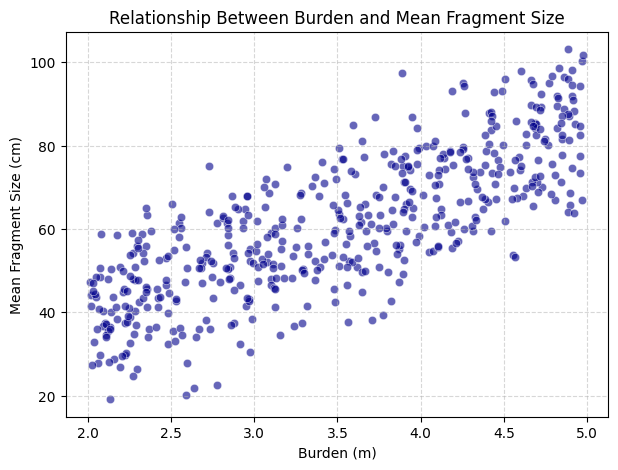

In [3]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='Burden_m', y='Mean_Fragment_Size_cm', color='darkblue', alpha=0.6)
plt.title("Relationship Between Burden and Mean Fragment Size")
plt.xlabel("Burden (m)")
plt.ylabel("Mean Fragment Size (cm)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Step 4: Markdown Explanation Cell

What do the statistics tell you about your data?
The descriptive statistics provide a baseline for our features and target values. The mean and median give us the central tendency, showing whether data is evenly distributed or skewed. The range, variance, and standard deviation quantify the dispersion or spread of the data, confirming that our parameters have enough variability (e.g., standard deviation and range values across burden and UCS) for a machine learning model to learn patterns rather than memorizing constant values.


The positive correlation coefficient between Burden and Mean Fragment Size indicates that as the burden distance increases, the resulting fragment size tends to increase. This makes physical sense in blasting engineering because a larger burden requires more energy to break, often resulting in coarser fragmentation if the explosive charge is not adjusted accordingly.

Does correlation necessarily mean that one variable causes the other?
No. Correlation does not imply causation. While domain knowledge confirms that increasing the burden physically causes coarser fragmentation due to increased confinement and reduced specific energy distribution, statistical correlation alone only shows a mathematical association. Other hidden or confounding factors (like rock jointing or explosive type) could also influence the outcome.

Step 5: Input-to-Output Mathematical ExpressionTo express the predictive relationship in our model:Input $\rightarrow$ Function/Model $\rightarrow$ OutputInput ($X$): Burden_mFunction ($f$): Trained Machine Learning Regression Model (e.g., Random Forest or Linear Function)Output ($y$)